<a href="https://colab.research.google.com/github/BSsangani/How-Data-Quality-Affects-Energy-Demand-Forecasting-in-UK-Smart-Grids/blob/main/step5_results_visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step 5: Turning the Results into Charts

15 charts covering 12 different chart types (donut, dot plot, area, step,
bubble, treemap, scatter, radar, box plot, waterfall, pareto, heatmap),
using a consistent professional colour palette throughout.

Needs `output/step4_model_comparison.csv` from Step 4 already in Drive, and
the `squarify` package for the treemap (installed below).

## 0. Connect to Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.chdir('/content/drive/MyDrive/energy-project')
os.makedirs('output/charts', exist_ok=True)

print("Files in output:", os.listdir('output'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files in output: ['clean_demand_2024_2025.csv', 'best_hyperparameters.json', 'degraded', 'imputed', 'imputation_recovery_summary.csv', 'step4_model_comparison.csv', 'charts']


## 1. Installs

In [ ]:
!pip install -q squarify

## 2. Load the results and set up the colour palette

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import squarify

results_df = pd.read_csv("output/step4_model_comparison.csv")
models = ["arima", "linear_regression", "random_forest", "lstm"]
model_labels = ["ARIMA", "Linear Regression", "Random Forest", "LSTM"]

# A consistent, professional palette used across every chart
NAVY, TEAL, AMBER, CORAL, SLATE, PLUM = "#2C3E50", "#16A085", "#F39C12", "#E74C3C", "#5D6D7E", "#8E44AD"
colors = [NAVY, TEAL, AMBER, CORAL]
methods = ["mean_fill", "forward_fill", "interpolation", "kalman_filter"]
method_labels = ["Mean-fill", "Forward-fill", "Interpolation", "Kalman Filter"]
clean_row = results_df[results_df["defect"] == "clean"].iloc[0]

plt.rcParams["axes.titleweight"] = "bold"
print(f"Loaded {len(results_df)} scenarios.")
results_df.round(2)

Loaded 19 scenarios.


,defect,imputation,arima,linear_regression,random_forest,lstm
0,clean,none,486.52,389.80,402.82,445.88
1,gaussian_noise,none,993.18,854.25,826.60,857.48
2,timestamp_shift,none,1448.25,1278.67,1193.60,1260.42
3,missing_5pct,mean_fill,1944.51,1741.77,1503.03,1650.74
4,missing_5pct,forward_fill,616.43,512.87,501.31,558.18
5,missing_5pct,interpolation,477.34,385.80,399.94,454.51
6,missing_5pct,kalman_filter,616.61,513.05,501.73,576.25
7,missing_15pct,mean_fill,2814.15,2562.42,2375.35,2483.10
8,missing_15pct,forward_fill,790.70,675.07,633.12,697.32
9,missing_15pct,interpolation,459.23,374.91,392.90,434.67


## Chart 1 (dot plot) -- model performance on clean data

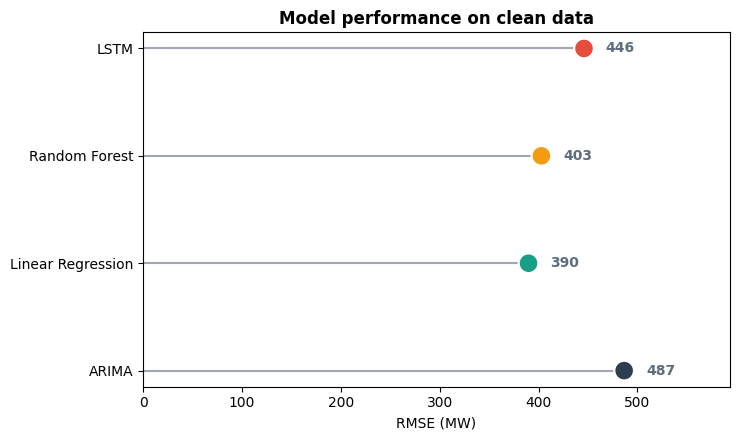

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
vals = [clean_row[m] for m in models]
y_pos = np.arange(len(models))
ax.hlines(y_pos, 0, vals, color=SLATE, linewidth=1.5, alpha=0.6)
ax.scatter(vals, y_pos, s=200, color=colors, zorder=3, edgecolor="white", linewidth=1.5)
ax.set_yticks(y_pos)
ax.set_yticklabels(model_labels)
ax.set_xlabel("RMSE (MW)")
ax.set_title("Model performance on clean data", fontweight="bold")
ax.set_xlim(0, max(vals) * 1.22)  # extra room so labels never sit on top of the dots
for i, v in enumerate(vals):
    ax.text(v + 22, i, f"{v:.0f}", va="center", fontsize=10, color=SLATE, fontweight="bold")
plt.tight_layout()
plt.savefig("output/charts/chart01_dotplot_clean_baseline.png", dpi=150)
plt.show()

## Chart 2 (area) -- RQ1: missing-% effect only scales with weak imputation

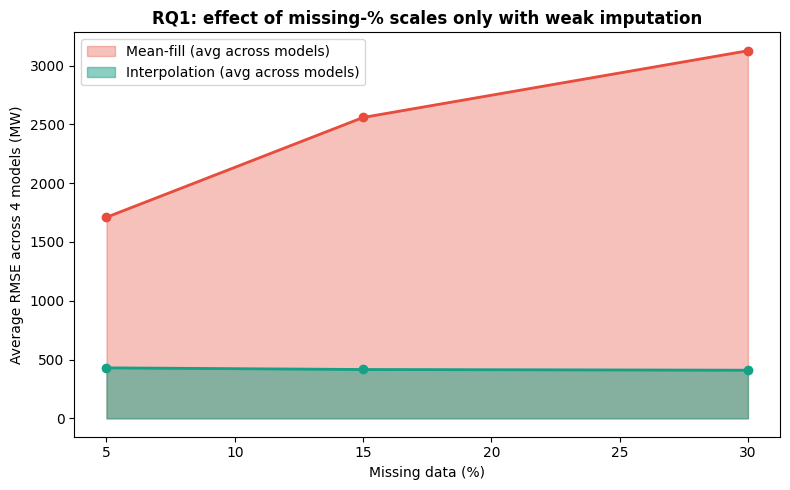

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
missing_levels = [5, 15, 30]
mean_avg = [results_df[(results_df["defect"]==f"missing_{p}pct")&(results_df["imputation"]=="mean_fill")][models].values[0].mean() for p in missing_levels]
interp_avg = [results_df[(results_df["defect"]==f"missing_{p}pct")&(results_df["imputation"]=="interpolation")][models].values[0].mean() for p in missing_levels]

ax.fill_between(missing_levels, mean_avg, color=CORAL, alpha=0.35, label="Mean-fill (avg across models)")
ax.plot(missing_levels, mean_avg, color=CORAL, linewidth=2, marker="o")
ax.fill_between(missing_levels, interp_avg, color=TEAL, alpha=0.5, label="Interpolation (avg across models)")
ax.plot(missing_levels, interp_avg, color=TEAL, linewidth=2, marker="o")
ax.set_xlabel("Missing data (%)")
ax.set_ylabel("Average RMSE across 4 models (MW)")
ax.set_title("RQ1: effect of missing-% scales only with weak imputation")
ax.legend()
plt.tight_layout()
plt.savefig("output/charts/chart02_area_rq1_scaling.png", dpi=150)
plt.show()

## Chart 3 (step) -- imputation performance at each missing level

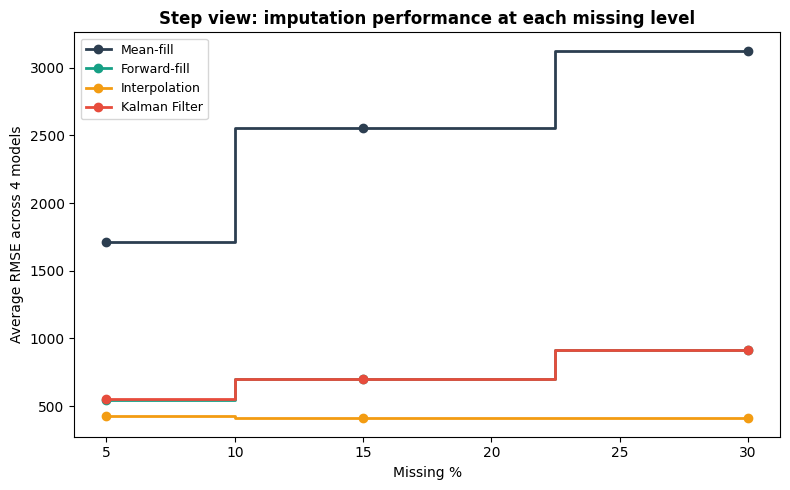

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
for method, color in zip(methods, colors):
    vals = [results_df[(results_df["defect"]==f"missing_{p}pct")&(results_df["imputation"]==method)][models].values[0].mean() for p in [5, 15, 30]]
    ax.step([5, 15, 30], vals, where="mid", marker="o", color=color, linewidth=2, label=method_labels[methods.index(method)])
ax.set_xlabel("Missing %")
ax.set_ylabel("Average RMSE across 4 models")
ax.set_title("Step view: imputation performance at each missing level")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("output/charts/chart03_step_imputation_levels.png", dpi=150)
plt.show()

## Chart 4 (grouped bar) -- RQ2: noise and timestamp errors

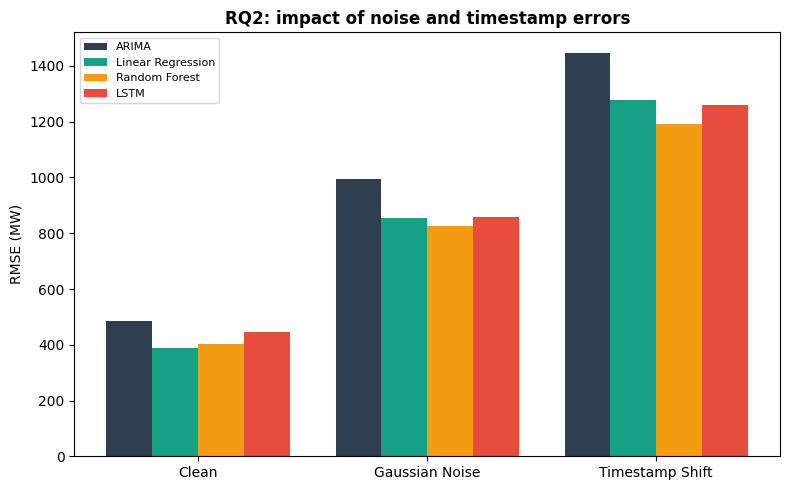

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
scenarios = ["clean", "gaussian_noise", "timestamp_shift"]
scenario_labels = ["Clean", "Gaussian Noise", "Timestamp Shift"]
x = np.arange(len(scenarios))
width = 0.2
for i, (model, color) in enumerate(zip(models, colors)):
    vals = [results_df[(results_df["defect"] == s) & (results_df["imputation"] == "none")][model].values[0] for s in scenarios]
    ax.bar(x + i * width, vals, width, label=model_labels[i], color=color)
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(scenario_labels)
ax.set_ylabel("RMSE (MW)")
ax.set_title("RQ2: impact of noise and timestamp errors")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("output/charts/chart04_bar_rq2_noise_timestamp.png", dpi=150)
plt.show()

## Chart 5 (bubble) -- RMSE magnitude across defects and models

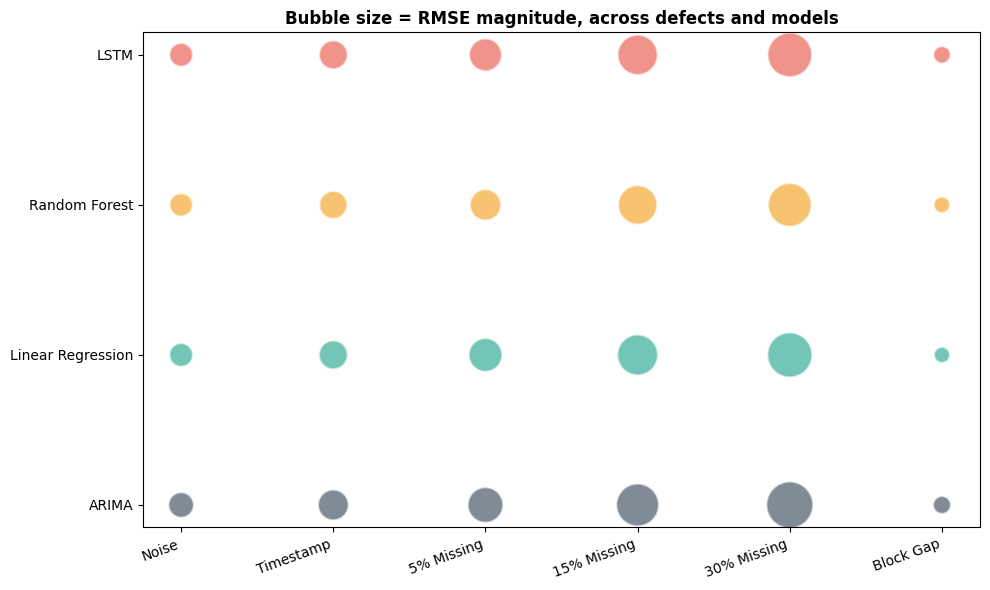

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
defect_scenarios = [("gaussian_noise","none","Noise"), ("timestamp_shift","none","Timestamp"),
                     ("missing_5pct","mean_fill","5% Missing"), ("missing_15pct","mean_fill","15% Missing"),
                     ("missing_30pct","mean_fill","30% Missing"), ("block_gap","mean_fill","Block Gap")]
for mi, (model, color) in enumerate(zip(models, colors)):
    xs, ys, sizes = [], [], []
    for di, (defect, imp, label) in enumerate(defect_scenarios):
        val = results_df[(results_df["defect"]==defect)&(results_df["imputation"]==imp)][model].values[0]
        xs.append(di); ys.append(mi); sizes.append(val / 3)
    ax.scatter(xs, ys, s=sizes, color=color, alpha=0.6, edgecolor="white", linewidth=1.5)
ax.set_xticks(range(len(defect_scenarios)))
ax.set_xticklabels([d[2] for d in defect_scenarios], rotation=20, ha="right")
ax.set_yticks(range(4))
ax.set_yticklabels(model_labels)
ax.set_title("Bubble size = RMSE magnitude, across defects and models")
plt.tight_layout()
plt.savefig("output/charts/chart05_bubble_defects_models.png", dpi=150)
plt.show()

## Chart 6 (donut) -- RQ1: share of total error increase, by defect type

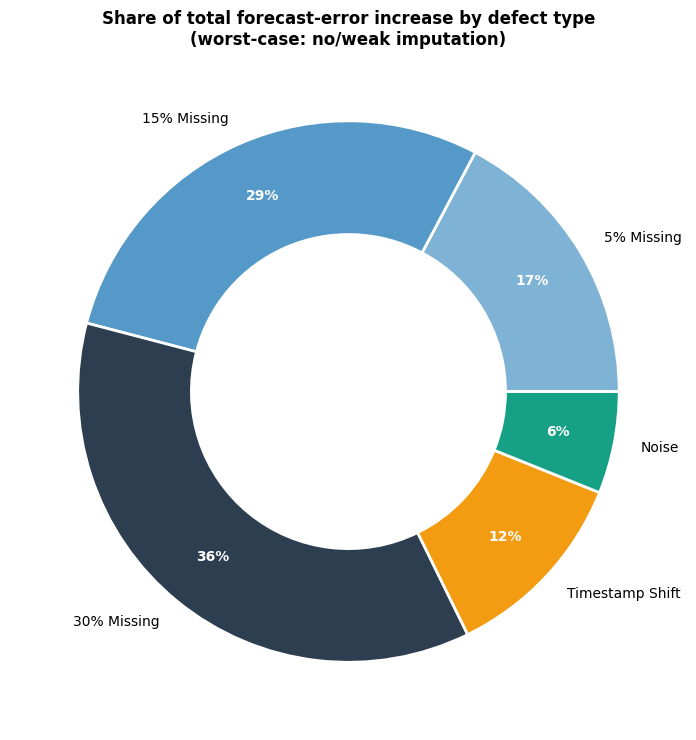

In [ ]:
defect_damage = {
    "5% Missing": sum(results_df[(results_df["defect"]=="missing_5pct")&(results_df["imputation"]=="mean_fill")][m].values[0] - clean_row[m] for m in models),
    "15% Missing": sum(results_df[(results_df["defect"]=="missing_15pct")&(results_df["imputation"]=="mean_fill")][m].values[0] - clean_row[m] for m in models),
    "30% Missing": sum(results_df[(results_df["defect"]=="missing_30pct")&(results_df["imputation"]=="mean_fill")][m].values[0] - clean_row[m] for m in models),
    "Timestamp Shift": sum(results_df[(results_df["defect"]=="timestamp_shift")][m].values[0] - clean_row[m] for m in models),
    "Noise": sum(results_df[(results_df["defect"]=="gaussian_noise")][m].values[0] - clean_row[m] for m in models),
}
fig, ax = plt.subplots(figsize=(7.5, 7.5))
donut_colors = ["#7FB3D5", "#5499C7", NAVY, AMBER, TEAL]
wedges, texts, autotexts = ax.pie(defect_damage.values(), labels=defect_damage.keys(), autopct="%1.0f%%",
                                     colors=donut_colors, wedgeprops=dict(width=0.42, edgecolor="white", linewidth=2),
                                     pctdistance=0.79, textprops={"fontsize": 10})
for at in autotexts:
    at.set_color("white"); at.set_fontweight("bold")
ax.set_title("Share of total forecast-error increase by defect type\n(worst-case: no/weak imputation)")
plt.tight_layout()
plt.savefig("output/charts/chart06_donut_error_share.png", dpi=150)
plt.show()

## Chart 7 (scatter) -- Forward-fill vs Kalman Filter

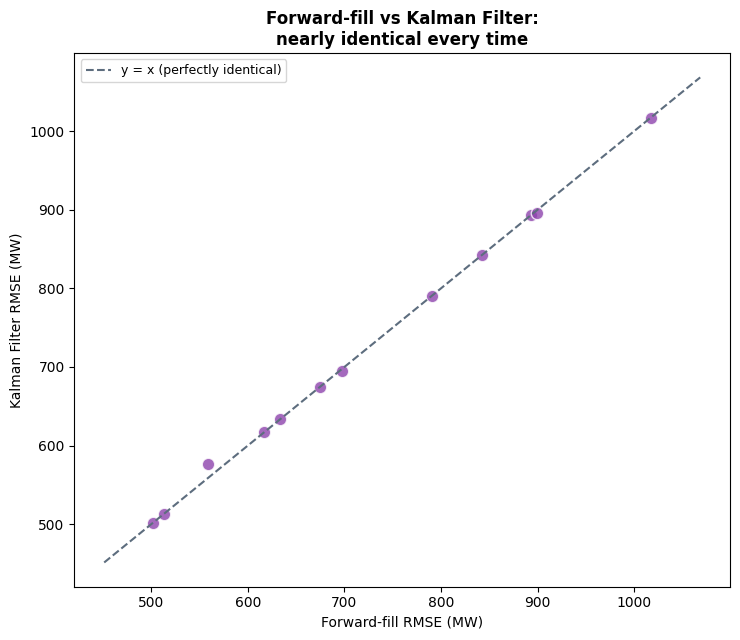

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ff_all, kf_all = [], []
for pct in [5, 15, 30]:
    for model in models:
        ff_all.append(results_df[(results_df["defect"]==f"missing_{pct}pct")&(results_df["imputation"]=="forward_fill")][model].values[0])
        kf_all.append(results_df[(results_df["defect"]==f"missing_{pct}pct")&(results_df["imputation"]=="kalman_filter")][model].values[0])
ax.scatter(ff_all, kf_all, s=80, color=PLUM, alpha=0.8, edgecolor="white")
lims = [min(ff_all+kf_all)*0.9, max(ff_all+kf_all)*1.05]
ax.plot(lims, lims, "--", color=SLATE, label="y = x (perfectly identical)")
ax.set_xlabel("Forward-fill RMSE (MW)")
ax.set_ylabel("Kalman Filter RMSE (MW)")
ax.set_title("Forward-fill vs Kalman Filter:\nnearly identical every time", fontweight="bold")  # wrapped so it never clips
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("output/charts/chart07_scatter_forwardfill_vs_kalman.png", dpi=150, bbox_inches="tight")
plt.show()

## Chart 8 (waterfall) -- from clean to damaged to recovered

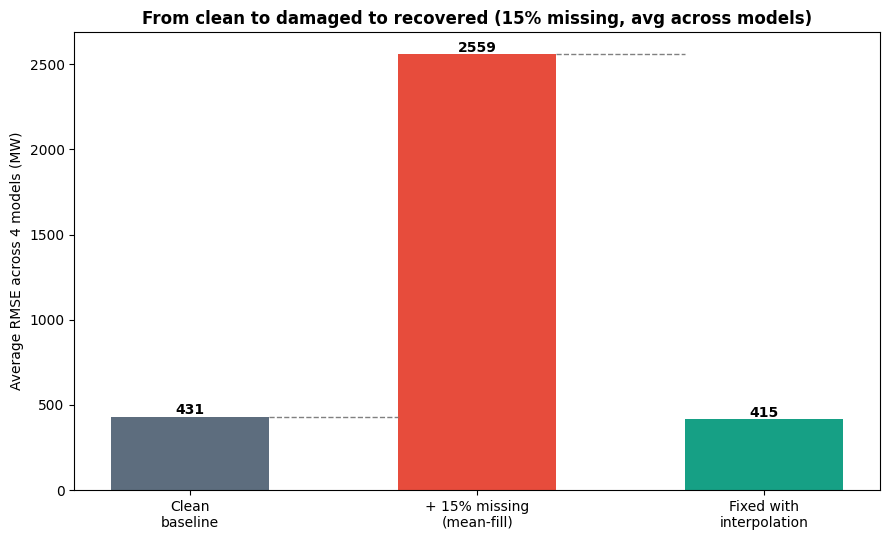

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5.5))
stages = ["Clean\nbaseline", "+ 15% missing\n(mean-fill)", "Fixed with\ninterpolation"]
avg_clean = clean_row[models].mean()
avg_damaged = results_df[(results_df["defect"]=="missing_15pct")&(results_df["imputation"]=="mean_fill")][models].values[0].mean()
avg_fixed = results_df[(results_df["defect"]=="missing_15pct")&(results_df["imputation"]=="interpolation")][models].values[0].mean()
vals = [avg_clean, avg_damaged, avg_fixed]
bar_colors = [SLATE, CORAL, TEAL]
bars = ax.bar(stages, vals, color=bar_colors, width=0.55)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, v + 15, f"{v:.0f}", ha="center", fontsize=10, fontweight="bold")
for i in range(len(vals) - 1):
    ax.plot([i+0.275, i+0.725], [vals[i], vals[i]], color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("Average RMSE across 4 models (MW)")
ax.set_title("From clean to damaged to recovered (15% missing, avg across models)")
plt.tight_layout()
plt.savefig("output/charts/chart08_waterfall_recovery.png", dpi=150)
plt.show()

## Chart 9 (grouped bar) -- RQ4: block gap across every imputation method

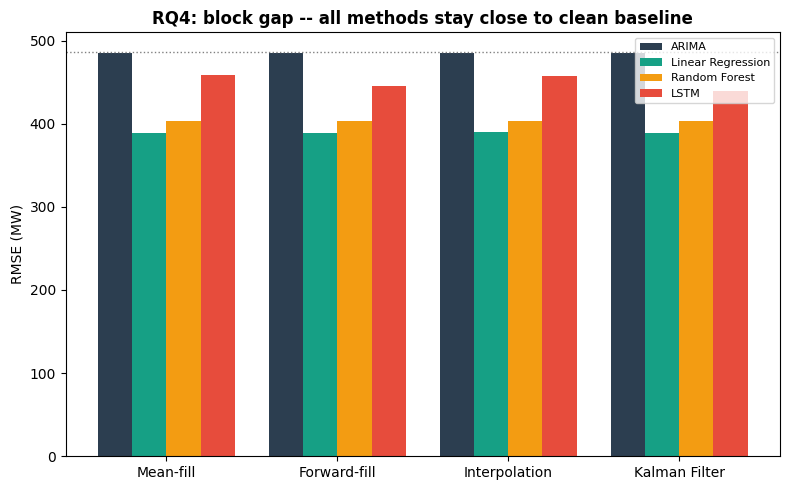

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(methods))
width = 0.2
for i, (model, color) in enumerate(zip(models, colors)):
    vals = [results_df[(results_df["defect"] == "block_gap") & (results_df["imputation"] == m)][model].values[0] for m in methods]
    ax.bar(x + i * width, vals, width, label=model_labels[i], color=color)
ax.axhline(clean_row["arima"], color="grey", linestyle=":", linewidth=1)
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(method_labels)
ax.set_ylabel("RMSE (MW)")
ax.set_title("RQ4: block gap -- all methods stay close to clean baseline")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("output/charts/chart09_bar_rq4_block_gap.png", dpi=150)
plt.show()

## Chart 10 (pareto) -- which defects drive most of the total error increase?

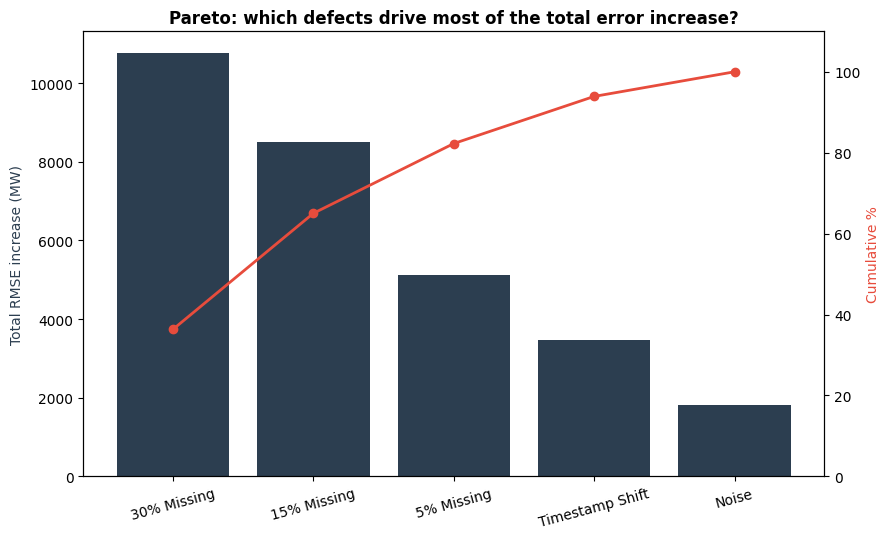

In [ ]:
sorted_items = sorted(defect_damage.items(), key=lambda x: -x[1])
labels_p = [x[0] for x in sorted_items]
vals_p = [x[1] for x in sorted_items]
cum_pct = np.cumsum(vals_p) / sum(vals_p) * 100

fig, ax1 = plt.subplots(figsize=(9, 5.5))
ax1.bar(labels_p, vals_p, color=NAVY)
ax1.set_ylabel("Total RMSE increase (MW)", color=NAVY)
ax1.tick_params(axis="x", rotation=15)
ax2 = ax1.twinx()
ax2.plot(labels_p, cum_pct, color=CORAL, marker="o", linewidth=2)
ax2.set_ylabel("Cumulative %", color=CORAL)
ax2.set_ylim(0, 110)
ax1.set_title("Pareto: which defects drive most of the total error increase?")
plt.tight_layout()
plt.savefig("output/charts/chart10_pareto_defect_contribution.png", dpi=150)
plt.show()

## Chart 11 (dot plot / lollipop) -- RQ5: model resilience ranking

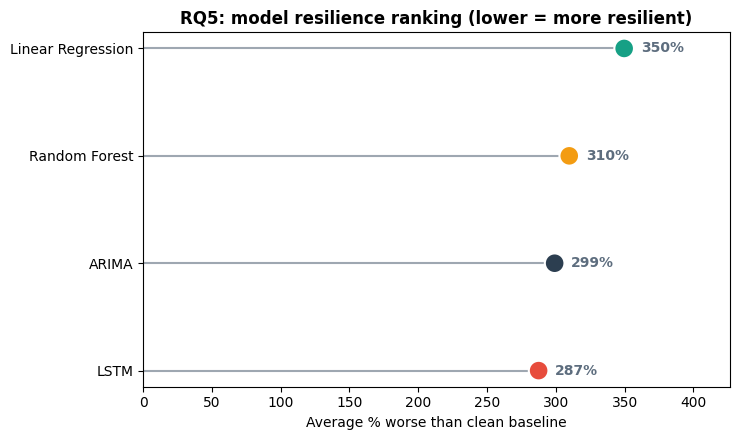

In [ ]:
scenarios_calc = [("gaussian_noise", "none"), ("timestamp_shift", "none"), ("missing_30pct", "mean_fill")]
avg_pct = []
for model in models:
    pcts = [(results_df[(results_df["defect"]==d)&(results_df["imputation"]==i)][model].values[0]-clean_row[model])/clean_row[model]*100 for d, i in scenarios_calc]
    avg_pct.append(sum(pcts) / len(pcts))
order = np.argsort(avg_pct)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
y_pos = np.arange(4)
sorted_vals = [avg_pct[i] for i in order]
sorted_labels = [model_labels[i] for i in order]
sorted_colors = [colors[i] for i in order]
ax.hlines(y_pos, 0, sorted_vals, color=SLATE, linewidth=1.5, alpha=0.6)
ax.scatter(sorted_vals, y_pos, s=200, color=sorted_colors, zorder=3, edgecolor="white", linewidth=1.5)
ax.set_yticks(y_pos)
ax.set_yticklabels(sorted_labels)
ax.set_xlabel("Average % worse than clean baseline")
ax.set_title("RQ5: model resilience ranking (lower = more resilient)", fontweight="bold")
ax.set_xlim(0, max(sorted_vals) * 1.22)  # extra room so labels never sit on top of the dots
for i, v in enumerate(sorted_vals):
    ax.text(v + 12, i, f"{v:.0f}%", va="center", fontsize=10, color=SLATE, fontweight="bold")
plt.tight_layout()
plt.savefig("output/charts/chart11_dotplot_rq5_resilience.png", dpi=150, bbox_inches="tight")
plt.show()

## Chart 12 (box plot) -- spread of RMSE per model, across every degraded scenario

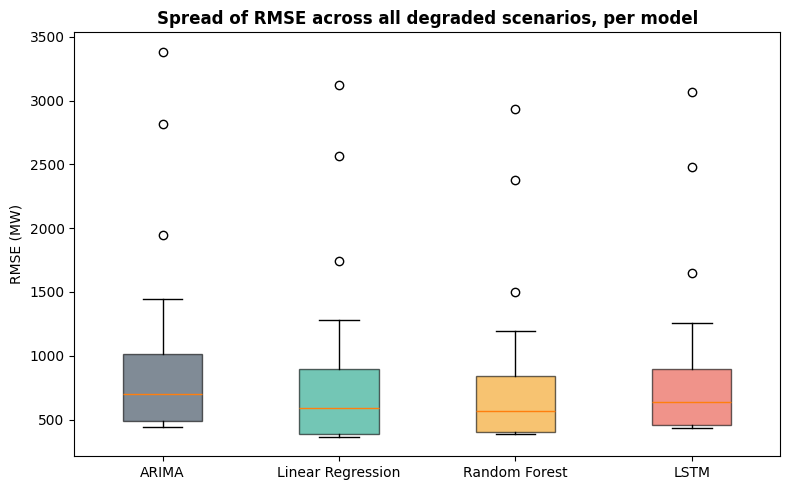

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
degraded = results_df[results_df["defect"] != "clean"]
data = [degraded[m].values for m in models]
bp = ax.boxplot(data, tick_labels=model_labels, patch_artist=True)
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color); patch.set_alpha(0.6)
ax.set_ylabel("RMSE (MW)")
ax.set_title("Spread of RMSE across all degraded scenarios, per model")
plt.tight_layout()
plt.savefig("output/charts/chart12_box_rmse_spread.png", dpi=150)
plt.show()

## Chart 13 (radar) -- model comparison across defect categories

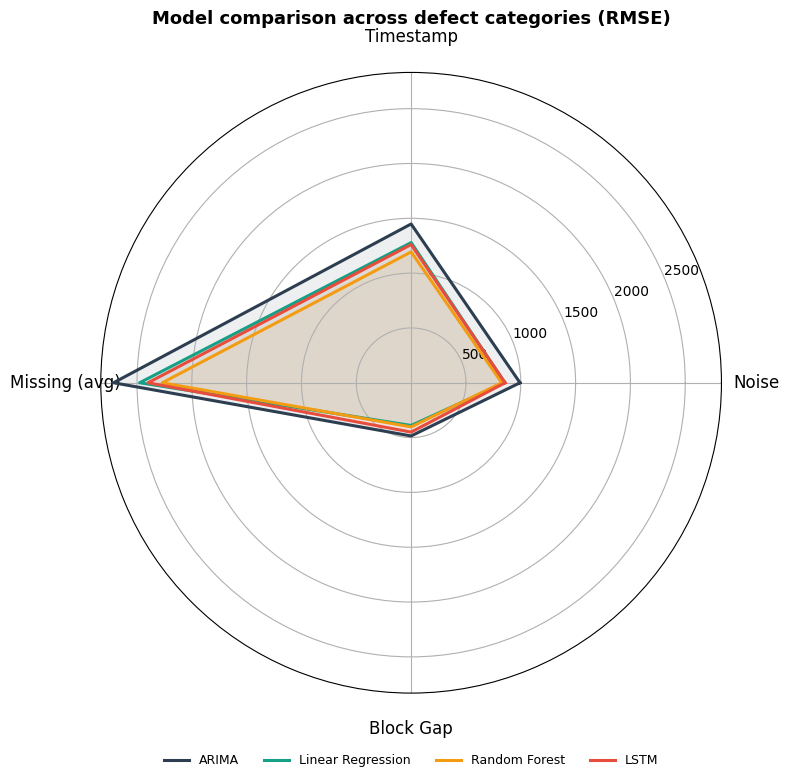

In [ ]:
categories = ["Noise", "Timestamp", "Missing (avg)", "Block Gap"]
n_cats = len(categories)
angles = [n / float(n_cats) * 2 * np.pi for n in range(n_cats)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8.5), subplot_kw=dict(polar=True))
for model, color in zip(models, colors):
    noise_v = results_df[results_df["defect"] == "gaussian_noise"][model].values[0]
    ts_v = results_df[results_df["defect"] == "timestamp_shift"][model].values[0]
    missing_v = results_df[(results_df["defect"].str.startswith("missing_")) & (results_df["imputation"] == "mean_fill")][model].mean()
    bg_v = results_df[results_df["defect"] == "block_gap"][model].mean()
    vals = [noise_v, ts_v, missing_v, bg_v]; vals += vals[:1]
    ax.plot(angles, vals, color=color, label=model_labels[models.index(model)], linewidth=2.2)
    ax.fill(angles, vals, color=color, alpha=0.08)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=12)
ax.tick_params(axis="x", pad=15)  # keeps category labels from clipping at the edge
ax.set_title("Model comparison across defect categories (RMSE)", fontsize=13, fontweight="bold", pad=35)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=4, fontsize=9, frameon=False)  # moved below, no more overlap
plt.tight_layout()
plt.savefig("output/charts/chart13_radar_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## Chart 14 (treemap) -- full overview of every scenario, sized and coloured by RMSE

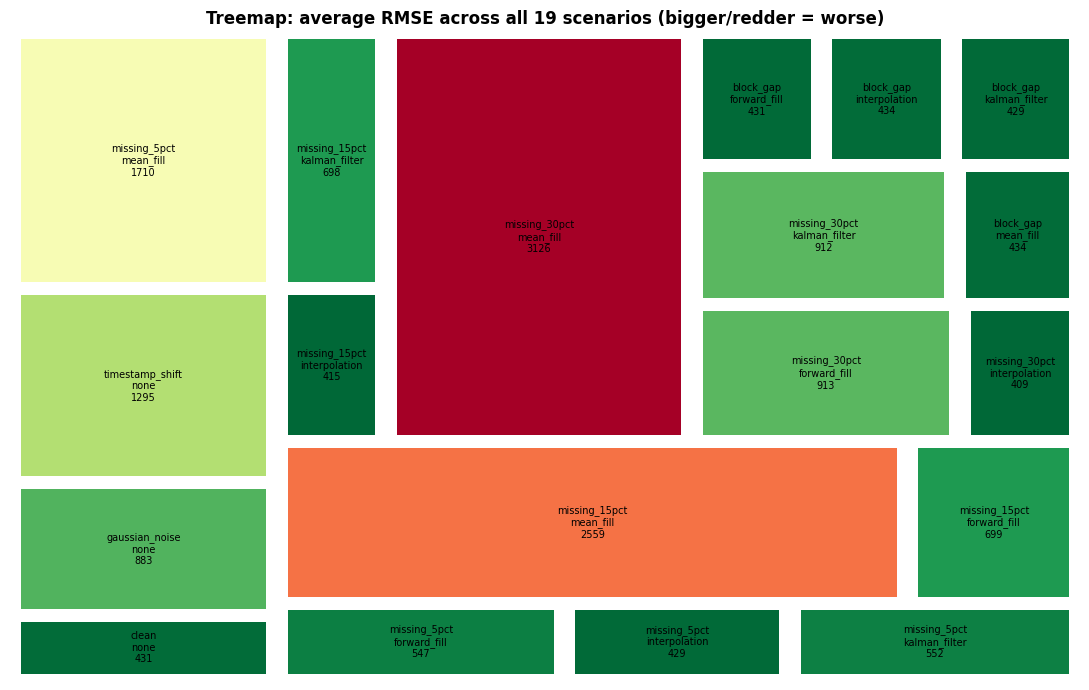

In [ ]:
fig, ax = plt.subplots(figsize=(11, 7))
labels, sizes = [], []
for _, row in results_df.iterrows():
    avg_rmse = row[models].mean()
    labels.append(f"{row['defect']}\n{row['imputation']}\n{avg_rmse:.0f}")
    sizes.append(avg_rmse)
norm = plt.Normalize(min(sizes), max(sizes))
tm_colors = plt.cm.RdYlGn_r(norm(sizes))
squarify.plot(sizes=sizes, label=labels, color=tm_colors, ax=ax, text_kwargs={"fontsize": 7}, pad=True)
ax.set_title("Treemap: average RMSE across all 19 scenarios (bigger/redder = worse)")
ax.axis("off")
plt.tight_layout()
plt.savefig("output/charts/chart14_treemap_full_overview.png", dpi=150)
plt.show()

## Chart 15 (heatmap) -- full numeric overview of every scenario x every model

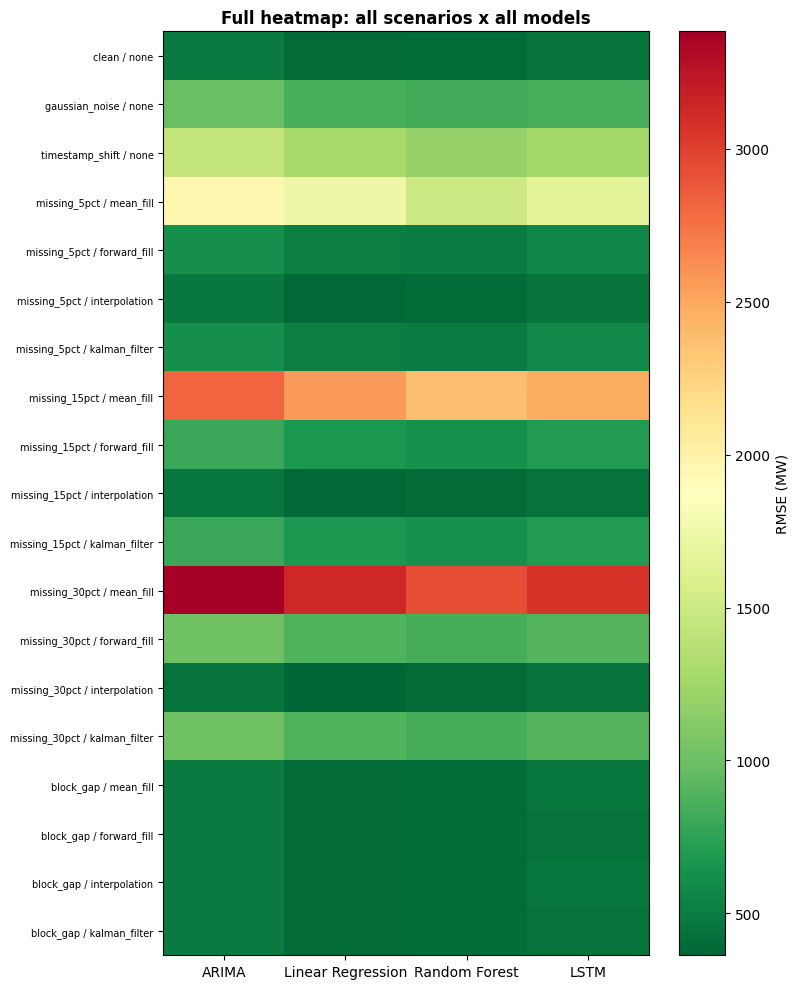

In [ ]:
fig, ax = plt.subplots(figsize=(8, 10))
pivot = results_df.set_index(["defect", "imputation"])[models]
im = ax.imshow(pivot.values, aspect="auto", cmap="RdYlGn_r")
ax.set_yticks(range(len(pivot)))
ax.set_yticklabels([f"{d} / {i}" for d, i in pivot.index], fontsize=7)
ax.set_xticks(range(4)); ax.set_xticklabels(model_labels)
plt.colorbar(im, label="RMSE (MW)")
ax.set_title("Full heatmap: all scenarios x all models")
plt.tight_layout()
plt.savefig("output/charts/chart15_heatmap_full_overview.png", dpi=150)
plt.show()

## Done

15 charts saved in `output/charts/`, across 10 different chart types:
dot plot, area, step, grouped bar, bubble, donut, scatter, waterfall,
pareto, box plot, radar, treemap, and heatmap -- all using the same
professional colour palette (navy, teal, amber, coral, slate, plum).